# Adversarial robustness

This notebook evaluates clean and adversarial performance under FGSM and 10-step PGD at ε = 2/255, 4/255, and 8/255.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'dense': '#111827', 'none': '#111827', 'attention': '#2563eb', 'mlp': '#d97706'}

def find_repo_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'results' / 'adverse_results.csv').exists():
            return candidate
    raise FileNotFoundError('Could not find results/adverse_results.csv. Run from this repository or its notebooks directory.')

ROOT = find_repo_root()
adv = pd.read_csv(ROOT / 'results' / 'adverse_results.csv')
for col in ['clean_accuracy', 'adversarial_accuracy', 'accuracy_drop', 'attack_success_rate']:
    adv[f'{col}_pct'] = adv[col] * 100
adv['pruning_pct'] = adv['requested_ratio'] * 100
adv['condition'] = adv['run_type'].map({'dense_adversarial': 'Dense', 'pruning_adversarial': 'Pruning only', 'retraining_adversarial': 'Retrained'})
adv['init_label'] = adv['init_method'].map({'dense_baseline': 'Dense baseline', 'dense_trained_weights': 'Dense trained weights', 'original_init': 'Original init', 'random_reinit': 'Random reinit'})
print(f'Rows: {len(adv)} | attacks: {sorted(adv.attack.unique())} | epsilon budgets: {sorted(adv.epsilon_x255.unique())}')

Rows: 150 | attacks: ['fgsm', 'pgd'] | epsilon budgets: [2.0, 4.0, 8.0]


In [2]:
# Focus table for the strongest iterative attack, PGD at epsilon = 8/255.
pgd8 = adv.query("attack == 'pgd' and epsilon_x255 == 8").copy()
pgd8_summary = pgd8[['condition', 'prune_type', 'pruning_pct', 'init_label', 'clean_accuracy_pct', 'adversarial_accuracy_pct', 'accuracy_drop_pct', 'attack_success_rate_pct']].sort_values(['condition', 'prune_type', 'pruning_pct', 'init_label'])
pgd8_summary.round(2)

,condition,prune_type,pruning_pct,init_label,clean_accuracy_pct,adversarial_accuracy_pct,accuracy_drop_pct,attack_success_rate_pct
5,Dense,none,0.0,Dense baseline,94.44,20.20,74.24,78.61
11,Pruning only,attention,20.0,Dense trained weights,94.26,20.74,73.52,77.99
17,Pruning only,attention,40.0,Dense trained weights,91.88,20.90,70.98,77.25
23,Pruning only,attention,60.0,Dense trained weights,71.50,5.80,65.70,91.89
29,Pruning only,attention,80.0,Dense trained weights,0.83,0.53,0.30,36.19
35,Pruning only,mlp,20.0,Dense trained weights,94.28,20.14,74.14,78.64
41,Pruning only,mlp,40.0,Dense trained weights,93.66,17.31,76.35,81.52
47,Pruning only,mlp,60.0,Dense trained weights,76.34,8.76,67.59,88.53
53,Pruning only,mlp,80.0,Dense trained weights,42.48,4.21,38.27,90.08
64,Retrained,attention,20.0,Original init,94.87,26.83,68.04,71.72


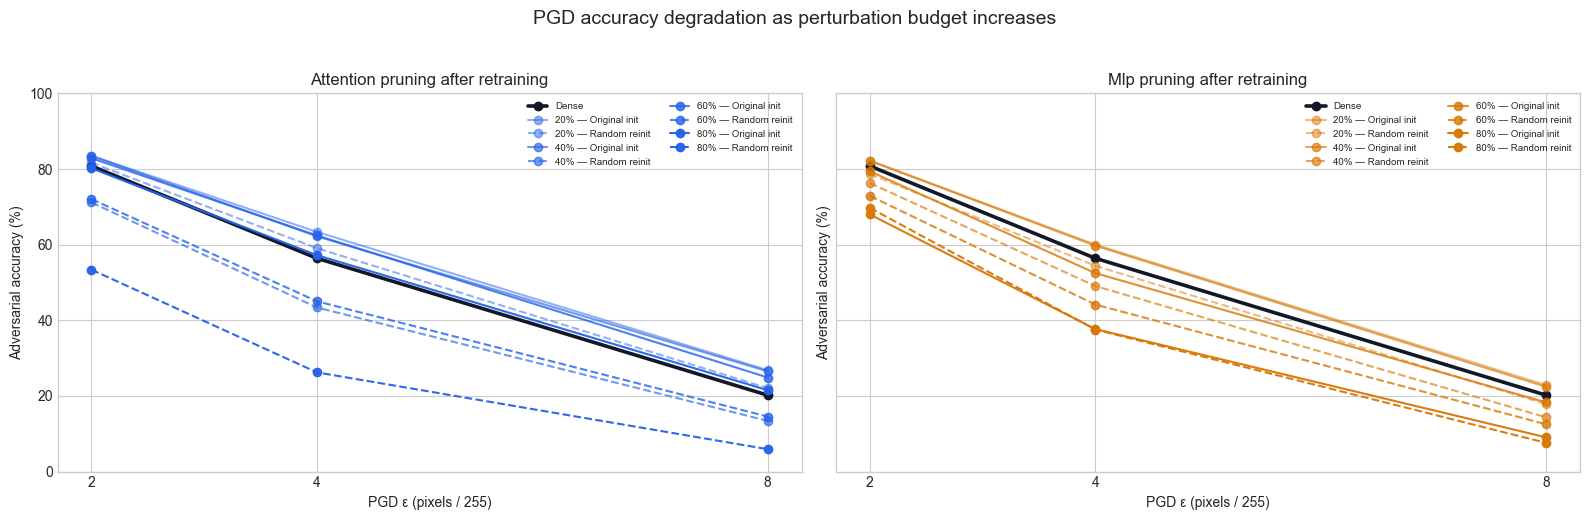

In [3]:
# 1. PGD robustness curves: plot the dense baseline plus each retraining configuration.
focus = pd.concat([
    adv.query("run_type == 'dense_adversarial' and attack == 'pgd'"),
    adv.query("run_type == 'retraining_adversarial' and attack == 'pgd'")
])
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for prune_type, ax in zip(['attention', 'mlp'], axes):
    dense = focus[focus['condition'].eq('Dense')]
    ax.plot(dense['epsilon_x255'], dense['adversarial_accuracy_pct'], color=COLORS['dense'], marker='o', linewidth=2.6, label='Dense')
    subset = focus[focus['prune_type'].eq(prune_type)]
    for (ratio, init), group in subset.groupby(['pruning_pct', 'init_label']):
        style = '-' if init == 'Original init' else '--'
        ax.plot(group['epsilon_x255'], group['adversarial_accuracy_pct'], color=COLORS[prune_type], linestyle=style, alpha=0.35 + ratio / 130, marker='o', label=f'{ratio:.0f}% — {init}')
    ax.set(title=f'{prune_type.title()} pruning after retraining', xlabel='PGD ε (pixels / 255)', ylabel='Adversarial accuracy (%)', xticks=[2, 4, 8], ylim=(0, 100))
    ax.legend(fontsize=7, ncol=2)
fig.suptitle('PGD accuracy degradation as perturbation budget increases', y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

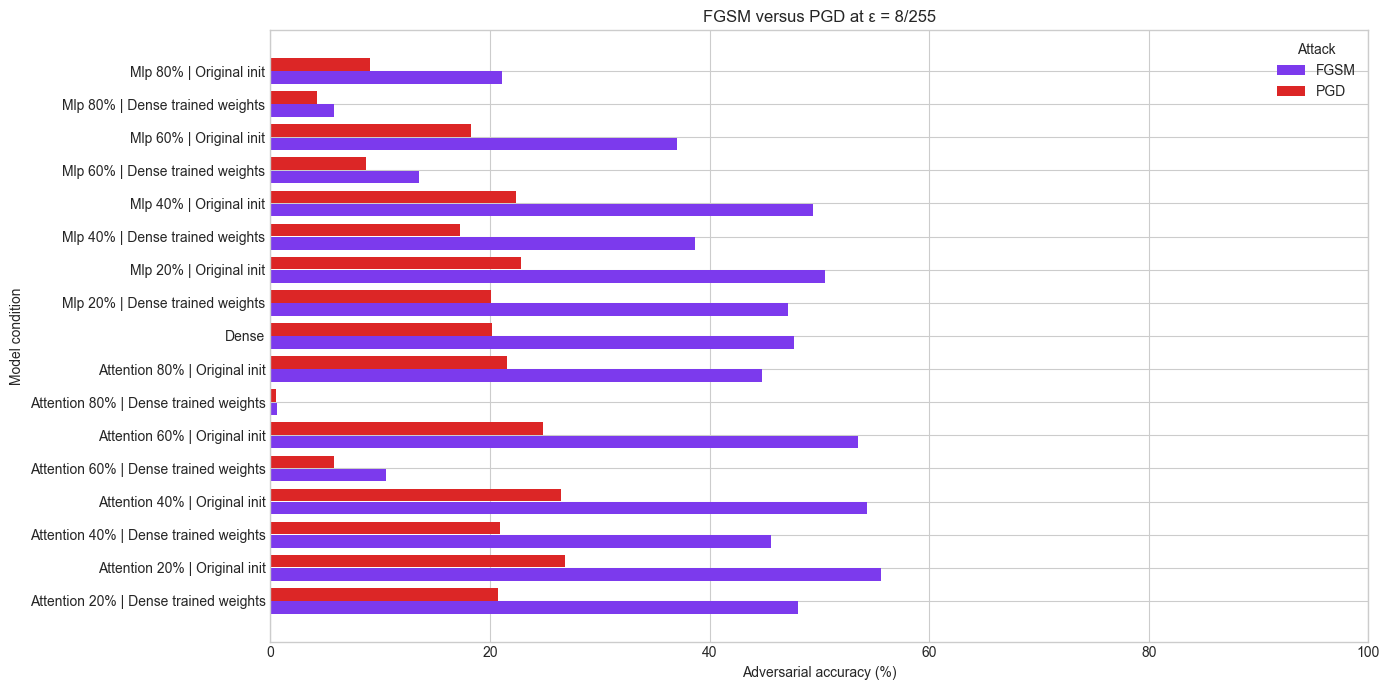

In [4]:
# 2. FGSM versus PGD at the largest perturbation budget.
eps8 = adv.query('epsilon_x255 == 8').copy()
eps8['model_label'] = eps8.apply(lambda r: 'Dense' if r['condition'] == 'Dense' else f"{r['prune_type'].title()} {r['pruning_pct']:.0f}% | {r['init_label']}", axis=1)
# Keep the plot legible: dense, pruning-only, and original-init retraining; the full data remain in eps8.
comparison = eps8[(eps8['condition'].eq('Dense')) | (eps8['condition'].eq('Pruning only')) | (eps8['init_label'].eq('Original init'))]
fig, ax = plt.subplots(figsize=(14, 7))
bar_data = comparison.pivot(index='model_label', columns='attack', values='adversarial_accuracy_pct').sort_index()
y = range(len(bar_data))
ax.barh([v - 0.2 for v in y], bar_data['fgsm'], height=0.38, color='#7c3aed', label='FGSM')
ax.barh([v + 0.2 for v in y], bar_data['pgd'], height=0.38, color='#dc2626', label='PGD')
ax.set_yticks(list(y), bar_data.index)
ax.set(title='FGSM versus PGD at ε = 8/255', xlabel='Adversarial accuracy (%)', ylabel='Model condition', xlim=(0, 100))
ax.legend(title='Attack')
plt.tight_layout()
plt.show()

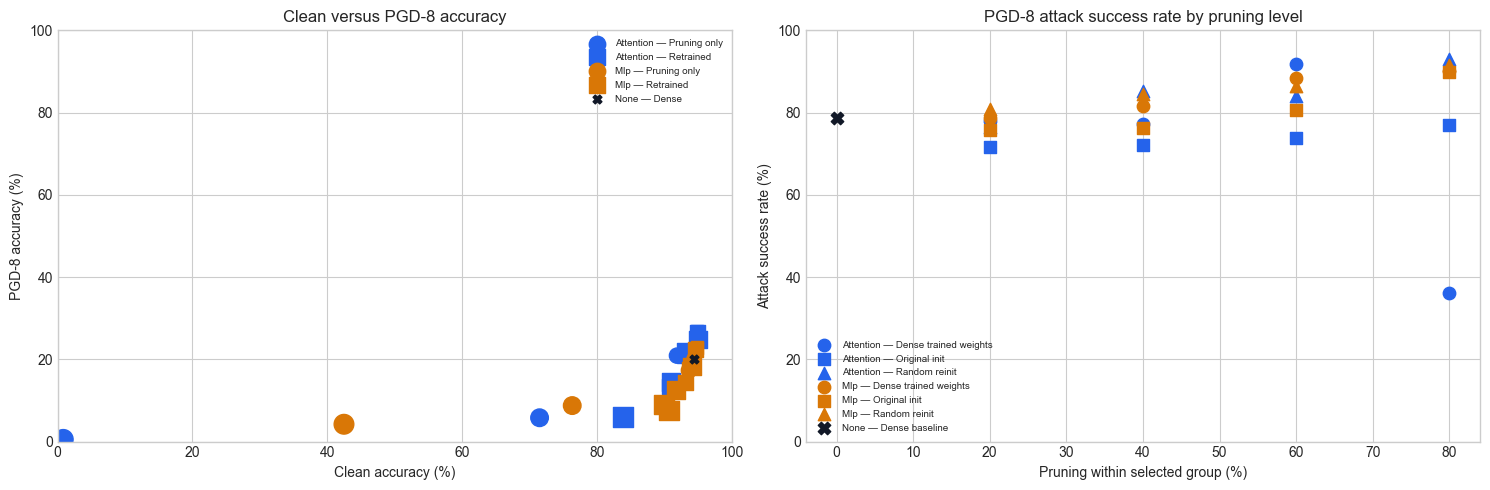

clean_accuracy_pct  \
condition    prune_type init_label                                  
Dense        none       Dense baseline                      94.44   
Pruning only attention  Dense trained weights               64.62   
             mlp        Dense trained weights               76.69   
Retrained    attention  Original init                       94.55   
                        Random reinit                       89.87   
             mlp        Original init                       93.40   
                        Random reinit                       92.28   

                                               adversarial_accuracy_pct  \
condition    prune_type init_label                                        
Dense        none       Dense baseline                            20.20   
Pruning only attention  Dense trained weights                     11.99   
             mlp        Dense trained weights                     12.60   
Retrained    attention  Original init                             24.93   
                        Random reinit                             13.99   
             mlp        Original init                             18.15   
                        Random reinit                             13.07   

                                               attack_success_rate_pct  
condition    prune_type init_label                                      
Dense        none       Dense baseline                           78.61  
Pruning only attention  Dense trained weights                    70.83  
             mlp        Dense trained weights                    84.69  
Retrained    attention  Original init                            73.64  
                        Random reinit                            84.67  
             mlp        Original init                            80.69  
                        Random reinit                            85.88

In [5]:
# 3. Clean accuracy is not a robustness metric: show the PGD-8 trade-off and attack success rates.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for (prune_type, condition), group in pgd8.groupby(['prune_type', 'condition']):
    axes[0].scatter(group['clean_accuracy_pct'], group['adversarial_accuracy_pct'], color=COLORS[prune_type], marker={'Dense': 'X', 'Pruning only': 'o', 'Retrained': 's'}[condition], s=40 + group['pruning_pct'] * 2, label=f'{prune_type.title()} — {condition}')
axes[0].set(title='Clean versus PGD-8 accuracy', xlabel='Clean accuracy (%)', ylabel='PGD-8 accuracy (%)', xlim=(0, 100), ylim=(0, 100))
axes[0].legend(fontsize=7)

for (prune_type, init), group in pgd8.groupby(['prune_type', 'init_label']):
    axes[1].scatter(group['pruning_pct'], group['attack_success_rate_pct'], color=COLORS[prune_type], marker={'Dense baseline': 'X', 'Dense trained weights': 'o', 'Original init': 's', 'Random reinit': '^'}[init], s=80, label=f'{prune_type.title()} — {init}')
axes[1].set(title='PGD-8 attack success rate by pruning level', xlabel='Pruning within selected group (%)', ylabel='Attack success rate (%)', ylim=(0, 100))
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

# Higher is better for both clean and adversarial accuracy; attack success rate is conditioned on initially correct samples.
pgd8.groupby(['condition', 'prune_type', 'init_label'])[['clean_accuracy_pct', 'adversarial_accuracy_pct', 'attack_success_rate_pct']].mean().round(2)